<a href="https://colab.research.google.com/github/ishitamunshi/world_model_stacking/blob/main/notebooks/trajectory_scoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Planning Baseline

Switch the runtime to a GPU (**Runtime → Change runtime type → GPU**), then click **Runtime → Run all**.

This notebook downloads the simulator code, the frozen world model and policy, and the subgoal images, then runs validation scene `100038` twice: once with the policy alone and once with the baseline planner. With the default seed on our GPUs, the policy alone stacks one box and the planner stacks two; on a Colab T4 the result can differ slightly because it runs in float16. The whole notebook takes about 10 to 15 minutes.

After running it once, edit `GoalPlanningAgent` in the planner cell below to try your own planner.

In [1]:
import os, subprocess, sys
os.environ["MUJOCO_GL"] = "egl"
os.environ["MUJOCO_EGL_DEVICE_ID"] = "0"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["HF_HUB_DISABLE_XET"] = "1"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("installing system libraries", flush=True)
    env = dict(os.environ, DEBIAN_FRONTEND="noninteractive")
    subprocess.check_call(["apt-get", "update", "-qq"], env=env)
    subprocess.check_call(
        ["apt-get", "install", "-y", "-qq", "libegl1", "libgl1", "libgles2", "libglib2.0-0", "ffmpeg"],
        env=env,
    )

def missing(module):
    try:
        __import__(module)
        return False
    except Exception:
        return True

packages = []
if missing("mujoco"):
    packages.append("mujoco>=3.3,<4")
if missing("imageio_ffmpeg"):
    packages.append("imageio[ffmpeg]>=2.30")
if missing("huggingface_hub"):
    packages.append("huggingface_hub>=0.26")
if missing("matplotlib"):
    packages.append("matplotlib")
if packages:
    print("installing", ", ".join(packages), flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade-strategy", "only-if-needed", *packages])

import torch
if not torch.cuda.is_available():
    raise RuntimeError("No GPU is visible. In Colab: Runtime → Change runtime type → GPU, then Runtime → Run all.")
print("cuda", torch.cuda.get_device_name(0), flush=True)


installing system libraries
installing mujoco>=3.3,<4
cuda Tesla T4


In [2]:
import os, sys, tarfile
from pathlib import Path
os.environ["MUJOCO_GL"] = "egl"
os.environ["HF_HUB_DISABLE_XET"] = "1"

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "assignment" / "training" / "planning" / "agent.py").exists():
            return cand
    return None

ROOT = find_root()
if ROOT is None:
    dest = Path("/content") if Path("/content").exists() else Path("/tmp")
    ROOT = dest / "world-model-gym"
    marker = ROOT / "assignment" / "training" / "planning" / "agent.py"
    if not marker.exists():
        print("downloading code", flush=True)
        from huggingface_hub import hf_hub_download
        archive = hf_hub_download("YongYong/cis6280-stack-world-models-v2", "code/world-model-gym.tar", repo_type="model")
        with tarfile.open(archive) as tar:
            try:
                tar.extractall(dest, filter="data")
            except TypeError:
                tar.extractall(dest)
    if not marker.exists():
        raise FileNotFoundError(f"code download did not produce {marker}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
hand = ROOT / "assets" / "sharpa" / "wave_01" / "right_sharpa_wave" / "right_sharpa_wave.xml"
if not hand.exists():
    print("downloading hand assets", flush=True)
    __import__("subprocess").check_call([sys.executable, "scripts/fetch_assets.py"])
import assignment.training.planning.agent
print("code", ROOT, flush=True)

from assignment.training.data.task import StackTaskEnv, TaskConfig
_env = StackTaskEnv(TaskConfig(target_count=4, horizon=10, terminate_on_ground=False), 100038)
_env.reset(("init", 100038))
_env.env.resolution = 128
# render() returns the (front, side) camera tuple, each of shape (128, 128, 3).
_frames = list(_env.env.render())
_env.close()
print("render", _frames[0].shape, flush=True)

downloading code


world-model-gym.tar:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

code /content/world-model-gym
render (128, 128, 3)


In [3]:
import os, shutil
from pathlib import Path
os.environ["HF_HUB_DISABLE_XET"] = "1"
import torch
from huggingface_hub import hf_hub_download

CKPT = Path("/content/stack-baseline") if Path("/content").exists() else Path("/tmp/stack-baseline")
CKPT.mkdir(parents=True, exist_ok=True)
WM = CKPT / "smwm-c3.pt"
POLICY = CKPT / "df-smwm-c1-sigma04.pt"
GOALS = CKPT / "goals-every80.npz"

def fetch(repo, filename, dest, repo_type):
    if dest.exists() and dest.stat().st_size > 0:
        print("already downloaded", dest.name, flush=True)
        return dest
    print("downloading", filename, flush=True)
    src = hf_hub_download(repo, filename, repo_type=repo_type)
    shutil.copyfile(src, dest)
    return dest

fetch("YongYong/cis6280-stack-world-models-v2", "jepa/smwm-c3/model.pt", WM, "model")
fetch("YongYong/cis6280-stack-world-models-v2", "policy/df-smwm-c1-sigma04/policy.pt", POLICY, "model")
fetch("YongYong/cis6280-stack-datasets-v2", "goals/scripted-val100-every80/goals.npz", GOALS, "dataset")

# Point the policy checkpoint's encoder field to the local world-model file.
ckpt = torch.load(POLICY, map_location="cpu", weights_only=False)
ckpt["info"]["encoder"] = str(WM.resolve())
torch.save(ckpt, POLICY)
print("weights ready", WM.stat().st_size, POLICY.stat().st_size, GOALS.stat().st_size, flush=True)

downloading jepa/smwm-c3/model.pt


model.pt:   0%|          | 0.00/73.4M [00:00<?, ?B/s]

downloading policy/df-smwm-c1-sigma04/policy.pt


policy.pt:   0%|          | 0.00/157M [00:00<?, ?B/s]

downloading goals/scripted-val100-every80/goals.npz


goals.npz:   0%|          | 0.00/34.1M [00:00<?, ?B/s]

weights ready 73352395 156956837 34086423


## Subgoals

These are the subgoal images for scene `100038`, taken every 8 seconds from a scripted run. Each image shows the front wrist camera on the left and the side wrist camera on the right.

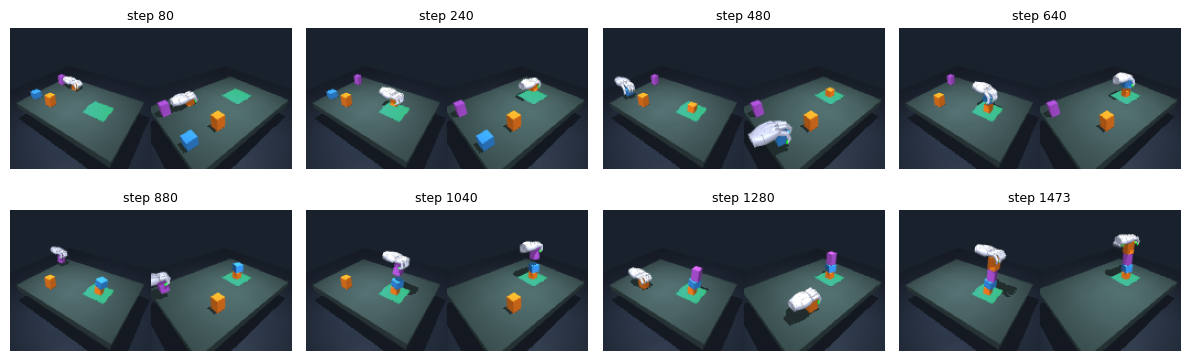

19 subgoals, every 80 control steps


In [4]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 100038
with np.load(GOALS) as goals:
    index = list(goals["seeds"]).index(SEED)
    count = int(goals["sub_count"][index])
    frames = goals["sub_frames"][index, :count]
    steps = goals["sub_steps"][index, :count]
shown = np.linspace(0, count - 1, num=min(count, 8), dtype=int)
fig, axes = plt.subplots(2, 4, figsize=(12, 4))
for ax, i in zip(axes.ravel(), shown):
    ax.imshow(frames[i])
    ax.set_title(f"step {int(steps[i])}", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(shown):]:
    ax.axis("off")
fig.tight_layout()
plt.show()
print(f"{count} subgoals, every 80 control steps")


## Baseline Planner (`GoalPlanningAgent`)

Without planning, `LatentPolicyAgent` samples one action chunk and executes its first block (5 control steps). With planning, `GoalPlanningAgent` samples 16 chunks, imagines each of them with the world model, and executes the first block of the chunk that ends closest to the current subgoal. It moves on to the next subgoal once the current frame is close enough to the active one.

To try your own planner for the competition, edit `GoalPlanningAgent` in the cell below and re-run the evaluation cell.

In [5]:
import numpy as np
import torch

from assignment.training.data.cache import RAW_ACTION_DIM, STRIDE
from assignment.training.planning.agent import LatentPolicyAgent


# ============================================================
# NEW: TRAJECTORY-AWARE COST FUNCTION
# ============================================================

def trajectory_score(pred, goal, alpha=0.0):
    """
    Compute a cost for each predicted action trajectory.

    Args:
        pred:  (N, H, 192) predicted latent trajectories
        goal:  (192,) target latent representation
        alpha: trajectory-cost weight between 0 and 1

    Returns:
        Tensor of shape (N,) with one cost per candidate.

    alpha = 0.0: Original terminal-distance baseline.
    alpha > 0.0: Include intermediate trajectory distances.
    """
    if not 0.0 <= alpha <= 1.0:
        raise ValueError("alpha must be between 0 and 1")

    # Distance of every predicted state from the goal.
    # Shape: (N, H)
    distances = (
        pred.float() - goal.float()
    ).square().sum(dim=-1)

    # Original baseline: only the final predicted state.
    # Shape: (N,)
    terminal_cost = distances[:, -1]

    # Increase the weight of later predicted states.
    horizon = distances.shape[1]

    weights = torch.arange(
        1,
        horizon + 1,
        device=distances.device,
        dtype=distances.dtype,
    )
    weights = weights / weights.sum()

    # Weighted cost across the entire trajectory.
    # Shape: (N,)
    path_cost = (distances * weights[None, :]).sum(dim=1)

    # Final combined cost.
    total_cost = (
        (1.0 - alpha) * terminal_cost
        + alpha * path_cost
    )

    return total_cost


# ============================================================
# GOAL PLANNING AGENT
# ============================================================

class GoalPlanningAgent(LatentPolicyAgent):
    """
    Model-predictive planner with configurable
    trajectory-aware action scoring.

    alpha = 0.0 reproduces the original scoring rule.
    """

    def __init__(
        self,
        policy_path,
        device="cuda",
        candidates=16,
        tau=0.25,
        alpha=0.0,
        **kwargs,
    ):
        super().__init__(policy_path, device, **kwargs)

        self.candidates = candidates
        self.tau = tau
        self.alpha = alpha

        self.goals = None
        self.last_score = None

    def reset(self, goal_frames=None, init_frame=None, seed=None):
        if goal_frames is not None and init_frame is None:
            raise ValueError(
                "init_frame is required with goal_frames"
            )

        super().reset(seed)

        self.frames = []
        self.executed = []
        self.index = 0

        self.last_distance = None
        self.last_score = None
        self.goals = None
        self.gap = None

        if goal_frames is not None:
            # Encode visual subgoals into latent representations.
            self.goals = self._encode(
                np.asarray(goal_frames)
            )

            prev = torch.cat([
                self._encode(np.asarray(init_frame)[None]),
                self.goals[:-1],
            ])

            self.gap = (
                self.goals - prev
            ).square().sum(-1)

    def goal_index(self, z):
        # Original fixed subgoal-switching rule.
        while (
            self.index < len(self.goals) - 1
            and (
                (z - self.goals[self.index])
                .square()
                .sum()
                < self.tau * self.gap[self.index]
            )
        ):
            self.index += 1

        return self.index

    @torch.no_grad()
    def _encode(self, frames):
        x = torch.from_numpy(
            np.ascontiguousarray(frames)
        ).to(self.device)[:, None]

        with self._autocast():
            return self.encoder.encode(x)[:, 0].float()

    @torch.no_grad()
    def step(self, frame):

        if self.goals is None:
            raise RuntimeError(
                "Call agent.reset(goal_frames, init_frame) "
                "before step()."
            )

        # 1. Encode current observation.
        z = self._encode(frame[None])[0]

        ctx = self.encoder.cfg.context

        self.frames = (
            self.frames + [z]
        )[-ctx:]

        self.history = (
            self.history
            + [(z - self.z_mean) / self.z_std]
        )[-self.policy.cfg.context:]

        goal = self.goals[self.goal_index(z)]

        if not self.queue:

            # 2. Generate candidate action sequences.
            pctx = (
                [self.history[0]]
                * (self.policy.cfg.context - len(self.history))
                + self.history
            )

            n = self.candidates

            blocks = self.policy.sample(
                torch.stack(pctx)[None].expand(n, -1, -1),
                self.generate,
                self.n_steps,
                self.lag,
                self.generator,
            )

            best = 0

            if n > 1:

                # 3. Predict candidate trajectories.
                past = (
                    self.executed[
                        len(self.executed) - len(self.frames) + 1:
                    ]
                    if len(self.frames) > 1
                    else []
                )

                acts = (
                    torch.cat([
                        torch.stack(past)[None].expand(n, -1, -1),
                        blocks,
                    ], dim=1)
                    if past
                    else blocks
                )

                with self._autocast():
                    pred = self.encoder.rollout(
                        torch.stack(self.frames)[None].expand(
                            n, -1, -1
                        ),
                        self.encoder.action_encoder(acts),
                        self.generate,
                    )

                # 4. Original terminal-distance metric.
                self.last_distance = (
                    pred[:, -1].float() - goal
                ).square().sum(-1)

                # NEW: Trajectory-aware candidate scoring.
                self.last_score = trajectory_score(
                    pred,
                    goal,
                    alpha=self.alpha,
                )

                # Select candidate with lowest total cost.
                best = int(self.last_score.argmin())

            # 5. Convert selected candidate to robot actions.
            raw = np.clip(
                blocks[best, :self.execute].cpu().numpy()
                * self.a_std
                + self.a_mean,
                -1,
                1,
            )

            self.queue = list(
                raw.reshape(-1, STRIDE, RAW_ACTION_DIM)
            )

        # 6. Execute the next action block.
        block = self.queue.pop(0)

        self.executed.append(
            torch.from_numpy(
                (block.reshape(-1) - self.a_mean)
                / self.a_std
            ).to(self.device)
        )

        return block


In [6]:
# Test trajectory scoring

torch.manual_seed(42)

pred = torch.randn(16, 16, 192, device="cuda")
goal = torch.randn(192, device="cuda")

# Original baseline calculation.
baseline = (pred[:, -1] - goal).square().sum(-1)

# Our scoring function.
score_0 = trajectory_score(pred, goal, alpha=0.0)
score_025 = trajectory_score(pred, goal, alpha=0.25)
score_05 = trajectory_score(pred, goal, alpha=0.5)

# The baseline and alpha=0 must match.
torch.testing.assert_close(baseline, score_0)

print("Baseline equivalence: PASS")
print("Candidate score shape:", score_025.shape)

print("\nBest candidate by cost function:")
print("Baseline:", baseline.argmin().item())
print("Alpha 0.00:", score_0.argmin().item())
print("Alpha 0.25:", score_025.argmin().item())
print("Alpha 0.50:", score_05.argmin().item())


Baseline equivalence: PASS
Candidate score shape: torch.Size([16])

Best candidate by cost function:
Baseline: 12
Alpha 0.00: 12
Alpha 0.25: 12
Alpha 0.50: 1


In [16]:

# ============================================================
# TRAJECTORY-AWARE PLANNING: FIRST SIMULATION EXPERIMENT
# ============================================================

import os
import time
import csv
import inspect
from pathlib import Path

import numpy as np

os.environ["MUJOCO_GL"] = "egl"

from assignment.training.data.cache import STRIDE
from assignment.training.data.recording import write_video
from assignment.training.data.signals import row_hand_parts
from assignment.training.data.task import StackTaskEnv, TaskConfig


# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

SEED = 100038
HORIZON = 1795

ALPHA = 0.1
CANDIDATES = 16
TAU = 0.25
GENERATE = 16
EXECUTE = 1

OUT = Path("/content/stack-baseline")
OUT.mkdir(parents=True, exist_ok=True)

# Confirm our modified planner accepts alpha.
assert "alpha" in inspect.signature(
    GoalPlanningAgent
).parameters, "Modified GoalPlanningAgent with alpha is not loaded."

print("=" * 55)
print("TRAJECTORY SCORING EXPERIMENT")
print("=" * 55)
print("Scene:", SEED)
print("Alpha:", ALPHA)
print("Candidates:", CANDIDATES)
print("Subgoal threshold:", TAU)
print("Horizon:", HORIZON)


# ------------------------------------------------------------
# 2. SIMULATION FUNCTION
# ------------------------------------------------------------

def run_trajectory_experiment(alpha):

    # Load visual subgoals for the selected scene.
    with np.load(GOALS) as goals:
        i = list(goals["seeds"]).index(SEED)
        n = int(goals["sub_count"][i])

        goal_frames = goals["sub_frames"][i, :n].copy()
        init_frame = goals["init_frames"][i].copy()

    # Initialize our modified planning agent.
    agent = GoalPlanningAgent(
        str(POLICY),
        "cuda",
        candidates=CANDIDATES,
        generate=GENERATE,
        execute=EXECUTE,
        tau=TAU,
        alpha=alpha,
    )

    agent.reset(
        goal_frames,
        init_frame,
        seed=SEED,
    )

    # Initialize MuJoCo environment.
    env = StackTaskEnv(
        TaskConfig(
            target_count=4,
            horizon=HORIZON,
            terminate_on_ground=False,
        ),
        SEED,
    )

    env.reset(("init", SEED))
    env.env.resolution = 128

    # Evaluation variables.
    frames = []
    max_placed = 0
    final_placed = 0
    grasped = False
    first_placement_step = None
    executed_steps = 0

    started = time.perf_counter()

    try:
        for step in range(HORIZON):

            # Generate an action block every STRIDE steps.
            if step % STRIDE == 0:

                frame = np.concatenate(
                    list(env.env.render()),
                    axis=1,
                )

                block = agent.step(frame)

                # Show current camera views and active subgoal.
                active_goal = goal_frames[
                    min(agent.index, len(goal_frames) - 1)
                ]

                view = np.concatenate(
                    [frame, active_goal],
                    axis=0,
                )

                frames.append(view)

                # Log progress.
                if step % 200 == 0:
                    print(
                        f"alpha={alpha:.2f} "
                        f"step={step:4d} "
                        f"max_boxes={max_placed}",
                        flush=True,
                    )

            # Execute one robot control action.
            _, _, terminated, truncated, info = env.step(
                block[step % STRIDE]
            )

            executed_steps = step + 1

            # Number of connected boxes currently stacked.
            placed = int(info["placed"])
            final_placed = placed

            # Track maximum stacking performance.
            max_placed = max(max_placed, placed)

            # Track when the first placement succeeds.
            if placed >= 1 and first_placement_step is None:
                first_placement_step = step + 1

            # Detect whether a grasp occurred.
            grasped = grasped or bool(
                (row_hand_parts(env.env.history[-1])[0] >= 2).any()
            )

            if terminated or truncated:
                break

    finally:
        env.close()

    elapsed_minutes = (
        time.perf_counter() - started
    ) / 60.0

    # --------------------------------------------------------
    # 3. SAVE VIDEO
    # --------------------------------------------------------

    alpha_tag = f"{int(round(alpha * 100)):03d}"

    video_path = OUT / (
        f"trajectory_alpha_{alpha_tag}_scene_{SEED}.mp4"
    )

    write_video(
        video_path,
        [f[None] for f in frames],
        STRIDE,
    )

    # --------------------------------------------------------
    # 4. COLLECT EVALUATION METRICS
    # --------------------------------------------------------

    result = {
        "scene_seed": SEED,
        "alpha": alpha,
        "candidates": CANDIDATES,
        "tau": TAU,
        "max_boxes_stacked": max_placed,
        "final_boxes_stacked": final_placed,
        "grasp_success": int(grasped),
        "first_placement_step": first_placement_step,
        "executed_steps": executed_steps,
        "runtime_minutes": round(elapsed_minutes, 2),
    }

    # Save results as CSV.
    csv_path = OUT / (
        f"metrics_alpha_{alpha_tag}_scene_{SEED}.csv"
    )

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(result.keys()),
        )
        writer.writeheader()
        writer.writerow(result)

    print("\n" + "=" * 55)
    print("EXPERIMENT COMPLETE")
    print("=" * 55)

    for key, value in result.items():
        print(f"{key}: {value}")

    print("\nVideo saved:", video_path)
    print("Metrics saved:", csv_path)

    return result


# ------------------------------------------------------------
# 5. RUN EXPERIMENT
# ------------------------------------------------------------

result_alpha_050 = run_trajectory_experiment(ALPHA)


TRAJECTORY SCORING EXPERIMENT
Scene: 100038
Alpha: 0.1
Candidates: 16
Subgoal threshold: 0.25
Horizon: 1795
alpha=0.10 step=   0 max_boxes=0
alpha=0.10 step= 200 max_boxes=0
alpha=0.10 step= 400 max_boxes=1
alpha=0.10 step= 600 max_boxes=1
alpha=0.10 step= 800 max_boxes=2
alpha=0.10 step=1000 max_boxes=2
alpha=0.10 step=1200 max_boxes=3
alpha=0.10 step=1400 max_boxes=3
alpha=0.10 step=1600 max_boxes=3

EXPERIMENT COMPLETE
scene_seed: 100038
alpha: 0.1
candidates: 16
tau: 0.25
max_boxes_stacked: 3
final_boxes_stacked: 3
grasp_success: 1
first_placement_step: 306
executed_steps: 1795
runtime_minutes: 5.1

Video saved: /content/stack-baseline/trajectory_alpha_010_scene_100038.mp4
Metrics saved: /content/stack-baseline/metrics_alpha_010_scene_100038.csv


In [17]:

# ============================================================
# DISPLAY TRAJECTORY SCORING RESULTS
# ============================================================

from IPython.display import Video, display, Markdown

alpha_tag = f"{int(round(ALPHA * 100)):03d}"

video_path = OUT / (
    f"trajectory_alpha_{alpha_tag}_scene_{SEED}.mp4"
)

csv_path = OUT / (
    f"metrics_alpha_{alpha_tag}_scene_{SEED}.csv"
)

display(Markdown(
    f"## Trajectory-Aware Planning: Alpha = {ALPHA:.2f}"
))

display(Video(
    str(video_path),
    embed=True,
    width=500,
))

display(Markdown("### Evaluation Results"))

print(f"Scene: {result_alpha_050['scene_seed']}")
print(f"Alpha: {result_alpha_050['alpha']}")
print(
    f"Maximum boxes stacked: "
    f"{result_alpha_050['max_boxes_stacked']}"
)
print(
    f"Final boxes stacked: "
    f"{result_alpha_050['final_boxes_stacked']}"
)
print(
    f"Grasp occurred: "
    f"{bool(result_alpha_050['grasp_success'])}"
)
print(
    f"First placement step: "
    f"{result_alpha_050['first_placement_step']}"
)
print(
    f"Runtime: "
    f"{result_alpha_050['runtime_minutes']} minutes"
)

print("\nSaved metrics:", csv_path)


## Trajectory-Aware Planning: Alpha = 0.10

### Evaluation Results

Scene: 100038
Alpha: 0.1
Maximum boxes stacked: 3
Final boxes stacked: 3
Grasp occurred: True
First placement step: 306
Runtime: 5.1 minutes

Saved metrics: /content/stack-baseline/metrics_alpha_010_scene_100038.csv


,scene_seed,alpha,candidates,tau,max_boxes_stacked,final_boxes_stacked,grasp_success,first_placement_step,executed_steps,runtime_minutes
0,100038,0.00,16,0.25,2,1,1,285,1795,5.23
1,100038,0.10,16,0.25,3,3,1,306,1795,5.10
2,100038,0.25,16,0.25,2,2,1,286,1795,4.98
3,100038,0.50,16,0.25,1,1,1,267,1795,5.18


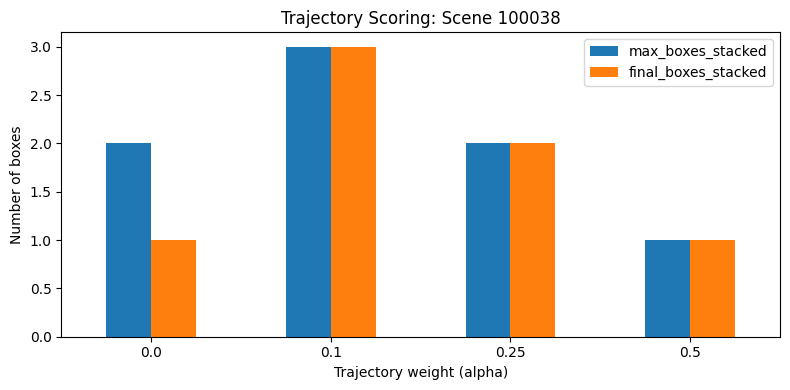

In [18]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

out = Path("/content/stack-baseline")

files = [
    out / f"metrics_alpha_{a:03d}_scene_100038.csv"
    for a in [0, 10, 25, 50]
]

df = pd.concat(
    [pd.read_csv(f) for f in files],
    ignore_index=True
).sort_values("alpha")

display(df)

ax = df.plot(
    x="alpha",
    y=["max_boxes_stacked", "final_boxes_stacked"],
    kind="bar",
    figsize=(8, 4)
)
ax.set_xlabel("Trajectory weight (alpha)")
ax.set_ylabel("Number of boxes")
ax.set_title("Trajectory Scoring: Scene 100038")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

df.to_csv(out / "alpha_comparison_scene_100038.csv",
          index=False)
